# The poke run: calibrated on GT_oct_2, tested on Ground_truth_oct_26_final

**The question:** the threshold calibrated on `GT_oct_2` does badly on `Ground_truth_oct_26_final` (called *OCT_oct_final* in conversation), worse than the Discobox's original software (the benchmark). That run is special: after its 30th recording the mites were poked, and the pokes pushed them around. Why does the detector fail there, is it the light (the bad mites are all on the top plates), what improves it, and how does the outline change between recordings (`classes/scoring/outline_change.py`) compare with the poke test?

**The data:** both runs were recorded before live runs followed their mites (28afd12, 20 October): every mite was scored in the box it was found in on the first frame, all run long. `scripts/poke_run_followed.py` scores every mite again from its saved ROI video, with its box as found (*fixed*) and as a live run would follow it today (*followed*, replayed from the blobs saved for each recording), with and without the stabilizer, and measures the outline change and the light round each mite. This notebook reads what it wrote (`results/scripts/poke_run_followed/`) and runs in seconds; the frames drawn in section 3 are read from the recordings.

Thresholds are chosen on `GT_oct_2` only, as the calibration report chooses them (`death_calibration.best_threshold()`: the smallest mean error in each mite's death). `Ground_truth_oct_26_final` is only tested on. It has 70 mites but labels for 26 (plates 3 to 6); the poke test covers 25 mites, 12 of them labelled.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from classes.ground_truth import death_calibration as dc
from classes.scoring.outline_change import OutlineChange
from classes.ground_truth.poke_test import PokeSurvival
from classes.storage.roi_recordings import open_recordings
from classes.results.survival import death_after

# The project's reporting module switches matplotlib to Agg (no figures) on import.
%matplotlib inline

# Chart style, as in death_time_calibration.ipynb: thin marks, recessive axes and grid, text in ink colours.
BLUE, ORANGE, AQUA, GREY, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85", "#7d5bd0"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)

OUT = ROOT / "results" / "scripts" / "poke_run_followed"
TRAIN, TEST = "GT_oct_2", "Ground_truth_oct_26_final"
runs = {name: json.loads((OUT / f"{name}.json").read_text(encoding="utf-8")) for name in (TRAIN, TEST)}
for run in runs.values():
    states = np.array(run["states"])
    run["labelled"], run["moving"] = (states == "moving") | (states == "still"), states == "moving"
    run["score"] = {"as recorded": np.array(run["app_scores"]),
                    **{kind: np.array(values) for kind, values in run["scores"].items()}}
    run["offset"] = np.array(run["offset"])
tr, te = runs[TRAIN], runs[TEST]


def threshold(kind):
    # the threshold the calibration report suggests, on GT_oct_2
    return dc.best_threshold([dc.LabelledRun(tr["score"][kind], tr["moving"], tr["labelled"])])[0]


def outcome(calls, run):
    # calls (mites, recordings) against the labels: per recording, and per mite's death (in recordings)
    labelled, moving = run["labelled"], run["moving"]
    c, y = calls[labelled], moving[labelled]
    tp, fp, fn, tn = (c & y).sum(), (c & ~y).sum(), (~c & y).sum(), (~c & ~y).sum()
    errors = dc.LabelledRun(np.zeros(calls.shape), moving, labelled).death_errors(calls)[moving.any(axis=1)]
    return {"F1": 2 * tp / max(2 * tp + fp + fn, 1), "balanced acc.": (tp / (tp + fn) + tn / (tn + fp)) / 2,
            "still called moving": int(fp), "moving called still": int(fn),
            "death error (rec.)": np.abs(errors).mean(), "deaths late": int((errors > 0).sum()),
            "deaths early": int((errors < 0).sum())}


def deaths(calls):
    # per mite, the recording after its last movement (0: never seen moving)
    return np.array([death_after(list(row)) for row in calls])


def outline_calls(run, kind="follow", skip_pushed=False):
    # the outline change's calls; with skip_pushed, a pair of recordings between which the
    # mite's followed box moved (it was pushed, or walked) says nothing
    pushed = np.c_[np.zeros(len(run["offset"]), bool), np.abs(np.diff(run["offset"], axis=1)) > 1]
    return np.array([OutlineChange().calls([None if (skip_pushed and pushed[m, at]) else value
                                            for at, value in enumerate(row)])
                     for m, row in enumerate(run["outline"][kind])])

## Findings (run of 20 October 2026)

- **It is the poke, not the light.** After the poke round following recording 29, the mites were pushed 10 to 35 px. Between recordings 29 and 47 some mites' boxes had to move in nearly every recording, so the plates were handled the whole time. A mite left lying at the edge of the box it was found in scores up to 100 (still mites on `GT_oct_2` stay under 0.2): the stabilizer follows the half of a body inside the box, and a sharp dark edge moved by a tenth of a pixel varies by about 10 grey levels. 171 of the detector's 182 false *moving* calls on the test run come from mites pushed out of their boxes (plates 4 and 5, recordings 30 to 44, and mite 6.2 from recording 44 on).
- **The light is steady.** Within a recording the frames' mean light varies by at most 0.21 grey levels. The plate's light round each mite moves by about ±1 grey level across the poke window. As recorded, the few recordings with a light shift above 2 grey levels are called moving more often (13 of 58, against 169 of 1740), but they are the ones in which the mites were pushed. With the mites followed the difference is gone (1 of 58, against 18 of 1740). The top plates were simply the ones poked.
- **Following the mites fixes it.** Replaying what live runs do since 28afd12 (each box moved to its blob at the start of each recording), the threshold calibrated on `GT_oct_2` (0.165) gives on the test run F1 **0.948** (0.719 as recorded; benchmark 0.928), 19 still recordings called moving instead of 182, and a mean death error of 2.96 recordings (11.5 as recorded; benchmark 2.35). The AUC goes from 0.941 to 0.991. The stabilizer then neither helps nor hurts here.
- **The rest are close calls.** With following, the remaining false calls score 0.16 to 0.48 (one 1.46). A review band of 0.12 to 0.5, about one check per mite, makes every labelled death on the test run exact. Without following, no band gets the error under 7 recordings.
- **On death time, the detector beats the benchmark once the labels are checked against the pokes** (section 8). Against the labels as they are, it is behind (2.96 recordings against 2.35). Its extra error is lone weak calls long after the labelled death, and they are not noise: a pixel on the mite's rim steps by 10 to 15 grey levels and stays, a leg tip moving, as in recordings labelled moving. The poke test contradicts 6 of the 26 labelled deaths, 5 of them by showing the mite alive after it was labelled dead. Against the labels corrected by the pokes, the detector's error is **2.23** and the benchmark's 3.81. Dropping lone weak calls looks good against the labels (1.15) but is worse against the corrected ones (2.69): it only agrees with the labels' mistakes. Checked by eye on the Discobox, 4 of the 7 lone late calls were real leg movements the labels had missed: with those corrected, the followed detector's death error is **0.92** recordings against the benchmark's 4.38 (F1 0.958 against 0.918).
- **Against the poke test, the followed detector does best.** Of the 25 poked mites it puts 13 deaths within what the pokes allow, 9 earlier (alive when poked but not seen moving since: no camera-only method can see those) and 3 later (two by one recording). As recorded: 12 late. The benchmark: 15 early. The labels themselves: 5 of 12 early.
- **The outline change between recordings fails against the poke test.** It calls 21 of the 25 poked mites alive after the poke they did not answer, 13 recordings late in the median. The pokes drag the mites' legs and turn them: that is a change between recordings, and the outline change was built to ignore only a rigid move. It keeps calling until recording 47, when the handling stops, then falls to the dead floor (0.026) at once. Skipping the pairs in which the mite was pushed halves that (+6 recordings), but a poke that drags a leg without moving the body still counts. Per recording against the labels it is also poor on both runs (F1 0.59 and 0.36): a live mite lying still within a recording changes its posture between recordings, so it measures *alive*, not *moving*, and is late by design (it needs two changed pairs in a row).

## 1. The two runs

In [2]:
rows = []
for name, run in runs.items():
    n_mites, n_recordings = run["labelled"].shape
    rows.append({"run": name, "mites": n_mites, "labelled mites": int(run["labelled"].any(axis=1).sum()),
                 "recordings": n_recordings, "every (min)": np.median(np.diff(run["times"])),
                 "length (h)": run["times"][-1] / 60, "moving labels": int(run["moving"].sum()),
                 "still labels": int((run["labelled"] & ~run["moving"]).sum()),
                 "poke rounds (after rec.)": ", ".join(str(r["after"]) for r in run["poke"]["rounds"]),
                 "poked mites": len(run["poke"]["bounds"])})
display(pd.DataFrame(rows).set_index("run"))

,mites,labelled mites,recordings,every (min),length (h),moving labels,still labels,poke rounds (after rec.),poked mites
run,,,,,,,,,
GT_oct_2,21,21,31,30.0,15.0,173,478,0,21
Ground_truth_oct_26_final,70,26,79,30.0,39.0,256,1798,"29, 30, 32, 34, 35, 37, 39, 40, 44",25


## 2. As recorded: calibrated on GT_oct_2, tested on the poke run

The scores are the app's own, as the calibration report caches them. *0.31* is the threshold in this laptop's `config.yaml`; the benchmark has nothing to calibrate.

In [3]:
t_recorded = threshold("as recorded")
rows = []
for label, calls in [(f"detector at {t_recorded:.3f} (calibrated)", lambda run: run["score"]["as recorded"] >= t_recorded),
                     ("detector at 0.31 (config.yaml)", lambda run: run["score"]["as recorded"] >= 0.31),
                     ("benchmark (Abilium)", lambda run: np.array(run["benchmark"]))]:
    for name, run in runs.items():
        rows.append({"method": label, "run": "calibrate" if name == TRAIN else "test", **outcome(calls(run), run)})
display(pd.DataFrame(rows).set_index(["method", "run"]))
labelled = te["labelled"]
print(f"AUC of the score: {roc_auc_score(tr['moving'][tr['labelled']], tr['score']['as recorded'][tr['labelled']]):.3f} "
      f"on GT_oct_2, {roc_auc_score(te['moving'][labelled], te['score']['as recorded'][labelled]):.3f} on the poke run")

F1  balanced acc.  \
method                         run                               
detector at 0.157 (calibrated) calibrate  0.988          0.992   
                               test       0.719          0.930   
detector at 0.31 (config.yaml) calibrate  0.905          0.913   
                               test       0.737          0.905   
benchmark (Abilium)            calibrate  0.895          0.905   
                               test       0.928          0.938   

                                          still called moving  \
method                         run                              
detector at 0.157 (calibrated) calibrate                    2   
                               test                       182   
detector at 0.31 (config.yaml) calibrate                    0   
                               test                       131   
benchmark (Abilium)            calibrate                    0   
                               test                         4   

                                          moving called still  \
method                         run                              
detector at 0.157 (calibrated) calibrate                    2   
                               test                        10   
detector at 0.31 (config.yaml) calibrate                   30   
                               test                        30   
benchmark (Abilium)            calibrate                   33   
                               test                        31   

                                          death error (rec.)  deaths late  \
method                         run                                          
detector at 0.157 (calibrated) calibrate               0.000            0   
                               test                   11.538           19   
detector at 0.31 (config.yaml) calibrate               0.571            0   
                               test                   10.077           16   
benchmark (Abilium)            calibrate               0.714            0   
                               test                    2.346            1   

                                          deaths early  
method                         run                      
detector at 0.157 (calibrated) calibrate             0  
                               test                  0  
detector at 0.31 (config.yaml) calibrate             6  
                               test                  0  
benchmark (Abilium)            calibrate             4  
                               test                  7

AUC of the score: 0.999 on GT_oct_2, 0.942 on the poke run


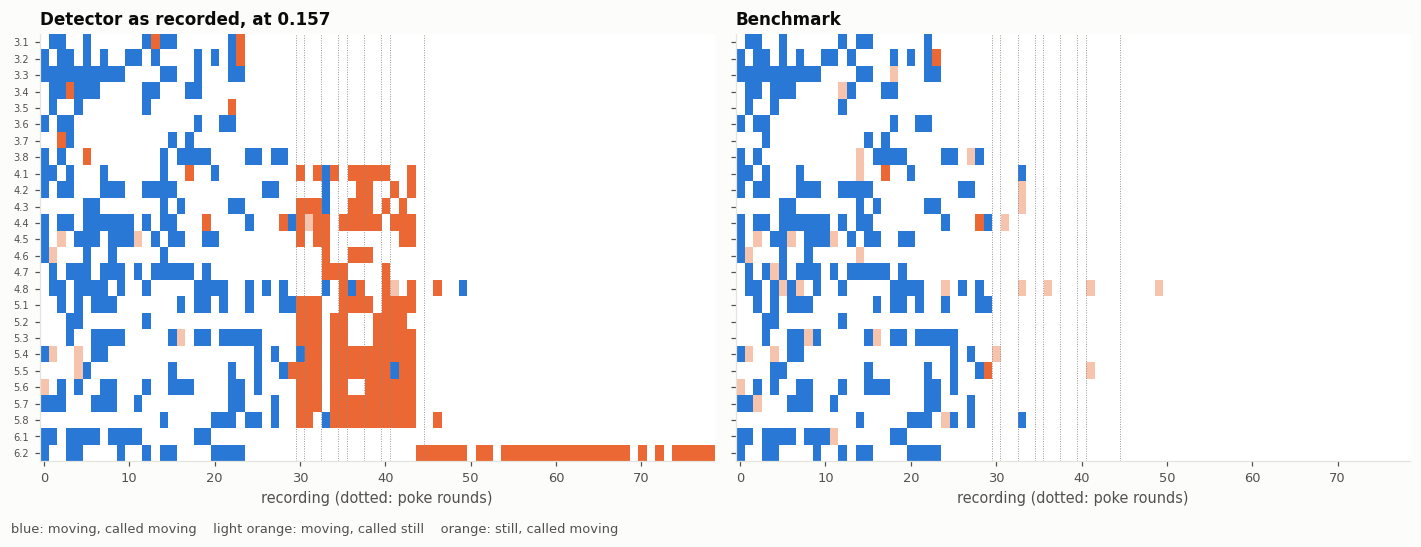

In [4]:
def call_map(ax, calls, run, title):
    # labelled mites x recordings: blue moving and called, light orange moving missed, orange still called moving
    rows = run["labelled"].any(axis=1)
    moving, calls = run["moving"][rows], calls[rows]
    image = np.ones((*moving.shape, 3))
    image[moving & calls] = plt.matplotlib.colors.to_rgb(BLUE)
    image[moving & ~calls] = plt.matplotlib.colors.to_rgb("#f6c3ad")
    image[~moving & calls] = plt.matplotlib.colors.to_rgb(ORANGE)
    ax.imshow(image, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(rows.sum()), np.array(run["ids"])[rows], fontsize=6.5)
    ax.set_title(title, loc="left")
    ax.grid(False)
    for after in (r["after"] for r in run["poke"]["rounds"]):
        ax.axvline(after + 0.5, color=GREY, lw=0.6, ls=":")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
call_map(axes[0], te["score"]["as recorded"] >= t_recorded, te, f"Detector as recorded, at {t_recorded:.3f}")
call_map(axes[1], np.array(te["benchmark"]), te, "Benchmark")
for ax in axes:
    ax.set_xlabel("recording (dotted: poke rounds)")
fig.text(0.01, -0.02, "blue: moving, called moving    light orange: moving, called still    orange: still, called moving",
         color=MUTED, fontsize=8.5)
plt.tight_layout()

## 3. What goes wrong: the poke pushes the mites out of their boxes

How far each labelled mite's followed box lies from where the mite was found (the push), and where the false calls are.

182 false calls as recorded, 171 of them on mites pushed more than 3 px from their box


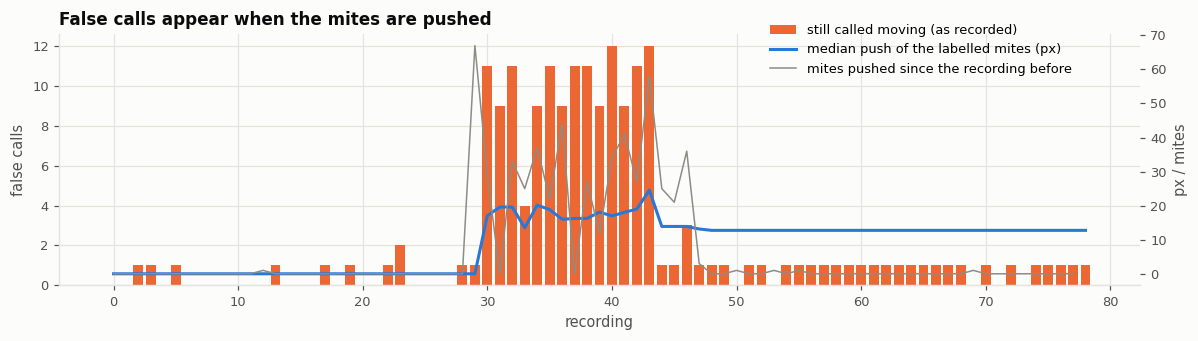

In [5]:
false_calls = (te["score"]["as recorded"] >= t_recorded) & te["labelled"] & ~te["moving"]
offset = te["offset"]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(range(false_calls.shape[1]), false_calls.sum(axis=0), color=ORANGE, label="still called moving (as recorded)")
ax2 = ax.twinx()
ax2.plot(np.median(offset[te["labelled"].any(axis=1)], axis=0), color=BLUE, label="median push of the labelled mites (px)")
ax2.plot((np.abs(np.diff(offset, axis=1)) > 1).sum(axis=0), color=GREY, lw=1, label="mites pushed since the recording before")
ax2.grid(False)
ax.set_xlabel("recording")
ax.set_ylabel("false calls")
ax2.set_ylabel("px / mites", color=MUTED)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.95))
ax.set_title("False calls appear when the mites are pushed", loc="left")
plt.tight_layout()
far = false_calls & (offset > 3)
print(f"{false_calls.sum()} false calls as recorded, {far.sum()} of them on mites pushed more than 3 px from their box")

Each pair of tiles is one mite in one recording, cut from its saved ROI: the mean of its frames, with the box it was found in (white, dashed) and the box following it (blue), then how much each pixel varies over the frames (the same scale everywhere). The second tile is flat noise in every case: nothing moves. Yet as recorded the scores reach 100.

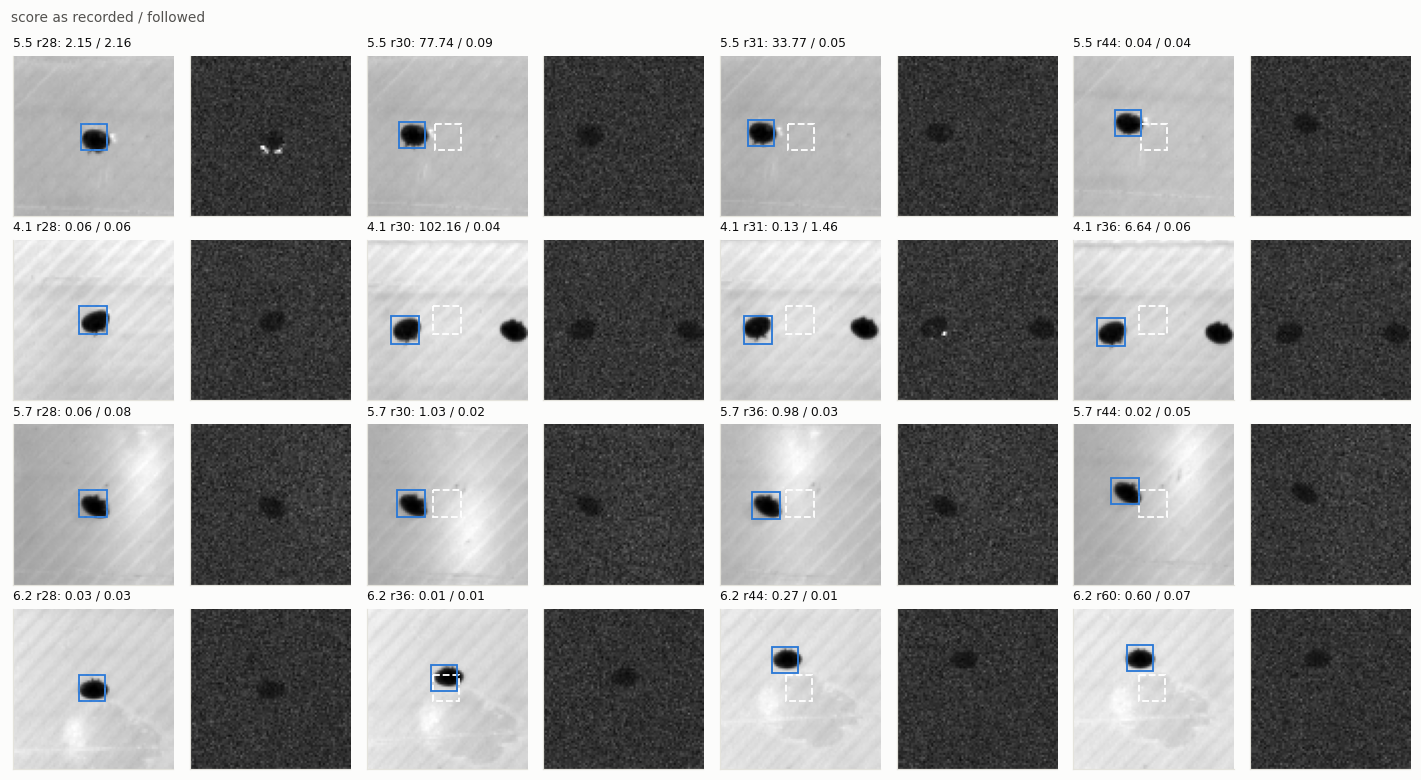

In [6]:
loader = open_recordings(ROOT / te["data_dir"]) if not Path(te["data_dir"]).is_absolute() else open_recordings(te["data_dir"])
roi_of = {number: mite["roi"] for number, mite in enumerate(loader.index["mites"])}
shown = {"5.5": (28, 30, 31, 44), "4.1": (28, 30, 31, 36), "5.7": (28, 30, 36, 44), "6.2": (28, 36, 44, 60)}
fig, axes = plt.subplots(len(shown), 8, figsize=(13, 7.2))
for row, (mite_id, recordings) in zip(axes, shown.items()):
    m = te["ids"].index(mite_id)
    number = te["roi_numbers"][m]
    x0, y0 = roi_of[number][:2]
    for (ax_mean, ax_var), at in zip(row.reshape(-1, 2), recordings):
        frames = loader.read_mite(te["recordings"][at], number).astype(np.float32)
        frames = frames.reshape(frames.shape[:3])
        ax_mean.imshow(frames.mean(axis=0), cmap="gray")
        ax_var.imshow(frames.std(axis=0), cmap="gray", vmin=0, vmax=8)
        for box, style in ((te["found_boxes"][m], dict(ec="white", ls="--")), (te["followed_boxes"][m][at], dict(ec=BLUE))):
            x1, y1, x2, y2 = box
            ax_mean.add_patch(plt.Rectangle((x1 - x0 - 0.5, y1 - y0 - 0.5), x2 - x1, y2 - y1, fill=False, lw=1.2, **style))
        ax_mean.set_title(f"{mite_id} r{at}: {te['score']['as recorded'][m, at]:.2f} / {te['score']['follow_stab'][m, at]:.2f}",
                          fontsize=8, fontweight="normal", loc="left")
        for ax in (ax_mean, ax_var):
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("score as recorded / followed", x=0.01, ha="left", fontsize=9, color=MUTED)
plt.tight_layout()

## 4. Is it the light?

The bad mites are all on the top plates, so the light was the first suspect: a lid opened, a lamp or the room's light. Three checks: whether the light varies within a recording (that is what the score sees), whether the plate's light round each mite (the median of its patch's rim, so a mite pushed out does not count) changes across the poke window, and whether the recordings with a light shift are called moving more often.

within a recording, the frames' mean light varies by at most 0.21 grey levels (99% under 0.14)
as recorded: still recordings called moving where the light shifted by more than 2 grey levels 13 of 58, elsewhere 169 of 1740
followed: still recordings called moving where the light shifted by more than 2 grey levels 1 of 58, elsewhere 18 of 1740


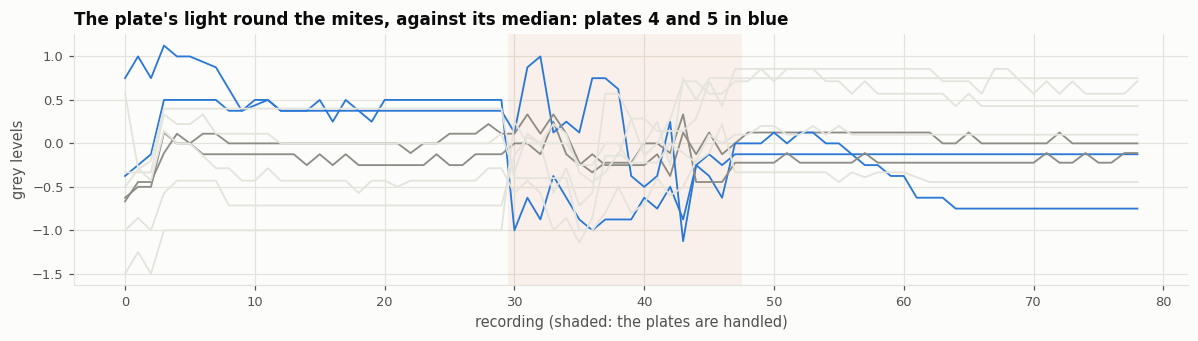

In [7]:
flicker = np.array(te["flicker"])
print(f"within a recording, the frames' mean light varies by at most {flicker.max():.2f} grey levels "
      f"(99% under {np.percentile(flicker, 99):.2f})")
light = np.array(te["light"])
shift = light - np.median(light, axis=1, keepdims=True)
zones = np.array(te["zones"])
fig, ax = plt.subplots(figsize=(11, 3.2))
for zone in sorted(set(zones)):
    ax.plot(shift[zones == zone].mean(axis=0), lw=1.2, label=f"plate {zone}",
            color=BLUE if zone in (4, 5) else GREY if zone in (3, 6) else GRID)
ax.axvspan(29.5, 47.5, color=ORANGE, alpha=0.08, lw=0)
ax.set_xlabel("recording (shaded: the plates are handled)")
ax.set_ylabel("grey levels")
ax.set_title("The plate's light round the mites, against its median: plates 4 and 5 in blue", loc="left")
plt.tight_layout()

followed = te["score"]["follow_stab"] >= threshold("follow_stab")
still = te["labelled"] & ~te["moving"]
for kind, calls in (("as recorded", te["score"]["as recorded"] >= t_recorded), ("followed", followed)):
    lit = np.abs(shift) > 2
    print(f"{kind}: still recordings called moving where the light shifted by more than 2 grey levels "
          f"{(calls & still & lit).sum()} of {(still & lit).sum()}, elsewhere {(calls & still & ~lit).sum()} of {(still & ~lit).sum()}")

## 5. Following the mites, as live runs do since 28afd12

Every mite scored four ways, each threshold calibrated on `GT_oct_2` alone. *as recorded* is the app's cache; *fixed / stab* is the same scored again by the script (it differs slightly where a neighbour's ROI overlaps), the check that the replay matches.

In [8]:
rows = []
for kind in ("as recorded", "fixed_stab", "fixed_raw", "follow_stab", "follow_raw"):
    t = threshold(kind)
    for name, run in runs.items():
        labelled = run["labelled"]
        rows.append({"boxes / stabilizer": kind.replace("_", " / "), "threshold": t, "run": "calibrate" if name == TRAIN else "test",
                     "AUC": roc_auc_score(run["moving"][labelled], run["score"][kind][labelled]),
                     **outcome(run["score"][kind] >= t, run)})
for name, run in runs.items():
    rows.append({"boxes / stabilizer": "benchmark", "threshold": np.nan, "run": "calibrate" if name == TRAIN else "test",
                 "AUC": np.nan, **outcome(np.array(run["benchmark"]), run)})
display(pd.DataFrame(rows).set_index(["boxes / stabilizer", "run"]))

threshold    AUC     F1  balanced acc.  \
boxes / stabilizer run                                                 
as recorded        calibrate      0.157  0.999  0.988          0.992   
                   test           0.157  0.942  0.719          0.930   
fixed / stab       calibrate      0.165  0.999  0.974          0.978   
                   test           0.165  0.941  0.722          0.929   
fixed / raw        calibrate      0.166  0.999  0.979          0.982   
                   test           0.166  0.988  0.867          0.959   
follow / stab      calibrate      0.165  0.999  0.974          0.978   
                   test           0.165  0.991  0.948          0.979   
follow / raw       calibrate      0.166  0.999  0.979          0.982   
                   test           0.166  0.991  0.947          0.979   
benchmark          calibrate        NaN    NaN  0.895          0.905   
                   test             NaN    NaN  0.928          0.938   

                              still called moving  moving called still  \
boxes / stabilizer run                                                   
as recorded        calibrate                    2                    2   
                   test                       182                   10   
fixed / stab       calibrate                    2                    7   
                   test                       178                   11   
fixed / raw        calibrate                    1                    6   
                   test                        63                   12   
follow / stab      calibrate                    2                    7   
                   test                        19                    8   
follow / raw       calibrate                    1                    6   
                   test                        20                    8   
benchmark          calibrate                    0                   33   
                   test                         4                   31   

                              death error (rec.)  deaths late  deaths early  
boxes / stabilizer run                                                       
as recorded        calibrate               0.000            0             0  
                   test                   11.538           19             0  
fixed / stab       calibrate               0.000            0             0  
                   test                   11.423           19             0  
fixed / raw        calibrate               0.000            0             0  
                   test                    8.154           17             0  
follow / stab      calibrate               0.000            0             0  
                   test                    2.962            7             0  
follow / raw       calibrate               0.000            0             0  
                   test                    2.962            7             0  
benchmark          calibrate               0.714            0             4  
                   test                    2.346            1             7

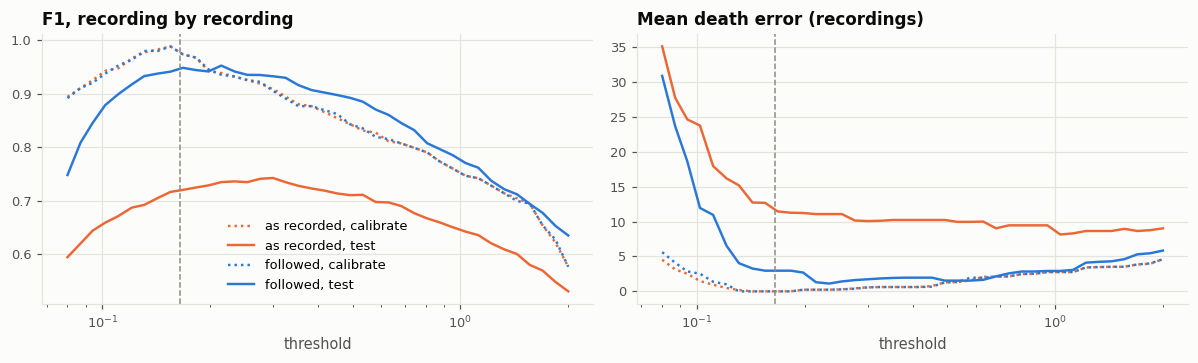

In [9]:
t_follow = threshold("follow_stab")
grid = np.round(np.geomspace(0.08, 2, 40), 3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for kind, color in (("as recorded", ORANGE), ("follow_stab", BLUE)):
    for name, run in runs.items():
        found = [outcome(run["score"][kind] >= t, run) for t in grid]
        style = dict(color=color, ls="-" if name == TEST else ":", lw=1.6,
                     label=f"{'followed' if kind != 'as recorded' else 'as recorded'}, {'test' if name == TEST else 'calibrate'}")
        axes[0].plot(grid, [f["F1"] for f in found], **style)
        axes[1].plot(grid, [f["death error (rec.)"] for f in found], **style)
for ax, title in zip(axes, ("F1, recording by recording", "Mean death error (recordings)")):
    ax.axvline(t_follow, color=GREY, lw=1, ls="--")
    ax.set_xscale("log"); ax.set_xlabel("threshold"); ax.set_title(title, loc="left")
axes[0].legend()
plt.tight_layout()

In [10]:
calls = te["score"]["follow_stab"] >= t_follow
wrong = np.argwhere(calls & te["labelled"] & ~te["moving"])
display(pd.DataFrame([{"mite": te["ids"][m], "recording": at, "score followed": te["score"]["follow_stab"][m, at],
                       "benchmark calls it moving": bool(te["benchmark"][m][at])} for m, at in wrong])
        .set_index(["mite", "recording"]).T)

mite                         3.1           3.2    3.4    3.5           3.7  \
recording                     13     23     23     3      22     33     2    
score followed             0.314  0.214  0.275  0.201  0.279  0.209  0.206   
benchmark calls it moving  False  False   True  False  False  False  False   

mite                         3.8    4.1                  4.4                \
recording                     5      17     31     40     19     35     42   
score followed             0.191  0.348  1.458  0.193  0.209  0.174  0.477   
benchmark calls it moving  False   True  False  False  False  False  False   

mite                                4.5    4.6    4.8    5.5  
recording                     43     31     38     30     29  
score followed             0.304  0.219  0.202   0.23  0.203  
benchmark calls it moving  False  False  False  False   True

## 6. What else helps: close calls checked by eye, and lone weak calls

With the mites followed, what is left is close calls. The results pages already ask to check the scores in a band round the threshold by eye (`classes/results/review_band.py`); here the labels stand in for the eye (`death_calibration.band_outcome()`, labelled mites only). Ignoring a lone weak call is a rule tried here, not in the app.

In [11]:
def labelled_run(run, kind):
    keep = run["labelled"].any(axis=1)
    return dc.LabelledRun(run["score"][kind], run["moving"], run["labelled"]).of_mites(keep)

rows = []
for kind, t in (("as recorded", t_recorded), ("follow_stab", t_follow)):
    for low, high in ((t, t), (0.12, 0.3), (0.12, 0.5), (0.1, 1.0), (0.1, 2.0)):
        for name, run in runs.items():
            found = dc.band_outcome([labelled_run(run, kind)], low, high)
            rows.append({"boxes": "followed" if kind != "as recorded" else "as recorded", "band": f"{low:.3g} to {high:.3g}",
                         "run": "calibrate" if name == TRAIN else "test", "checks per mite": found["checks_per_mite"],
                         "death error (rec.)": found["mae"], "deaths exact": found["exact"]})
display(pd.DataFrame(rows).pivot_table(index=["boxes", "band"], columns="run", sort=False,
                                       values=["checks per mite", "death error (rec.)", "deaths exact"]))

checks per mite        death error (rec.)          \
run                              calibrate   test          calibrate    test   
boxes       band                                                               
as recorded 0.157 to 0.157           0.000  0.000                0.0  11.538   
            0.12 to 0.3              0.381  1.154                0.0  10.077   
            0.12 to 0.5              0.571  1.269                0.0  10.038   
            0.1 to 1                 0.952  3.808                0.0   7.462   
            0.1 to 2                 1.190  4.346                0.0   6.962   
followed    0.12 to 0.3              0.429  0.769                0.0   0.462   
            0.12 to 0.5              0.619  1.000                0.0   0.000   
            0.1 to 1                 1.095  2.000                0.0   0.000   
            0.1 to 2                 1.333  2.231                0.0   0.000   
            0.165 to 0.165           0.000  0.000                0.0   2.962   

                           deaths exact         
run                           calibrate   test  
boxes       band                                
as recorded 0.157 to 0.157          1.0  0.269  
            0.12 to 0.3             1.0  0.385  
            0.12 to 0.5             1.0  0.385  
            0.1 to 1                1.0  0.423  
            0.1 to 2                1.0  0.462  
followed    0.12 to 0.3             1.0  0.962  
            0.12 to 0.5             1.0  1.000  
            0.1 to 1                1.0  1.000  
            0.1 to 2                1.0  1.000  
            0.165 to 0.165          1.0  0.731

In [12]:
def without_lone_weak(scores, t, strong=1.5, window=3):
    # a call under strong x t with no other call within `window` recordings is dropped
    calls = scores >= t
    out = calls.copy()
    for m, at in np.argwhere(calls & (scores < strong * t)):
        if calls[m, max(0, at - window):at + window + 1].sum() == 1:
            out[m, at] = False
    return out

rows = []
for strong in (1.5, 2, 3):
    for window in (1, 2, 3):
        for name, run in runs.items():
            rows.append({"under (x threshold)": strong, "within (rec.)": window, "run": "calibrate" if name == TRAIN else "test",
                         **outcome(without_lone_weak(run["score"]["follow_stab"], t_follow, strong, window), run)})
table = pd.DataFrame(rows).pivot_table(index=["under (x threshold)", "within (rec.)"], columns="run",
                                       values=["F1", "death error (rec.)", "deaths late", "deaths early"])
display(table)

F1        death error (rec.)         \
run                               calibrate   test          calibrate   test   
under (x threshold) within (rec.)                                              
1.5                 1                 0.949  0.951              0.238  1.154   
                    2                 0.968  0.951              0.143  1.154   
                    3                 0.971  0.953              0.000  1.154   
2.0                 1                 0.942  0.944              0.476  1.885   
                    2                 0.964  0.945              0.286  1.885   
                    3                 0.971  0.949              0.000  1.769   
3.0                 1                 0.929  0.938              0.667  1.962   
                    2                 0.961  0.944              0.476  1.885   
                    3                 0.968  0.949              0.190  1.769   

                                  deaths early      deaths late       
run                                  calibrate test   calibrate test  
under (x threshold) within (rec.)                                     
1.5                 1                      2.0  1.0         0.0  4.0  
                    2                      1.0  1.0         0.0  4.0  
                    3                      0.0  1.0         0.0  4.0  
2.0                 1                      4.0  5.0         0.0  3.0  
                    2                      2.0  5.0         0.0  3.0  
                    3                      0.0  4.0         0.0  3.0  
3.0                 1                      5.0  6.0         0.0  3.0  
                    2                      3.0  5.0         0.0  3.0  
                    3                      1.0  4.0         0.0  3.0

## 7. The poke test against the detector, the benchmark and the outline change between recordings

A poked mite that moved was alive up to that poke; one that did not is dead from it on (`PokeTest.bounds()`). Each method's death (the recording after its last movement) is *early* when it comes before a poke the mite answered, *late* when it comes after a poke the mite did not answer, and *within* otherwise. Early is expected of every camera-only method: a mite can answer a poke and never move by itself again. Late is an error.

In [13]:
methods = {
    "labels": te["moving"],
    "detector as recorded": te["score"]["as recorded"] >= t_recorded,
    "detector followed": te["score"]["follow_stab"] >= t_follow,
    "benchmark": np.array(te["benchmark"]),
    "outline change (fixed)": outline_calls(te, "fixed"),
    "outline change (followed)": outline_calls(te, "follow"),
    "outline change, pushed pairs skipped": outline_calls(te, "follow", skip_pushed=True),
}
bounds = te["poke"]["bounds"]
poked = [m for m, mite_id in enumerate(te["ids"]) if mite_id in bounds]
died = {name: deaths(calls) for name, calls in methods.items()}

table = pd.DataFrame({"plate": [te["zones"][m] for m in poked],
                      "answered until": [bounds[te["ids"][m]][0] for m in poked],
                      "dead from": [bounds[te["ids"][m]][1] for m in poked],
                      **{name: [died[name][m] if (name != "labels" or te["labelled"][m].any()) else None for m in poked]
                         for name in methods}},
                     index=pd.Index([te["ids"][m] for m in poked], name="mite"))
display(table)

rows = []
for name in methods:
    early = within = late = 0
    gaps = []
    for m in poked:
        if name == "labels" and not te["labelled"][m].any():
            continue
        alive_until, dead_from = bounds[te["ids"][m]]
        death = died[name][m]
        if alive_until is not None and death < alive_until:
            early += 1
        elif dead_from is not None and death > dead_from:
            late += 1
        else:
            within += 1
        if dead_from is not None:
            gaps.append(death - dead_from)
    rows.append({"method": name, "mites": early + within + late, "early": early, "within": within, "late": late,
                 "death - dead from, median": np.median(gaps), "mean |.|": np.mean(np.abs(gaps))})
display(pd.DataFrame(rows).set_index("method"))

,plate,answered until,dead from,labels,detector as recorded,detector followed,benchmark,outline change (fixed),outline change (followed),"outline change, pushed pairs skipped"
mite,,,,,,,,,,
3.8,3,30.0,31.0,29.0,29,29,29,48,48,45
4.2,4,30.0,35.0,34.0,44,34,28,48,48,47
4.3,4,30.0,33.0,34.0,43,34,24,48,48,48
4.4,4,30.0,NaN,32.0,44,44,30,48,48,47
4.5,4,30.0,33.0,21.0,44,32,21,46,46,30
4.6,4,30.0,41.0,15.0,39,39,9,48,48,47
4.7,4,30.0,40.0,20.0,41,20,20,48,48,48
5.3,5,30.0,35.0,26.0,44,26,26,48,45,28
5.4,5,30.0,33.0,31.0,44,31,28,46,46,29


,mites,early,within,late,"death - dead from, median",mean |.|
method,,,,,,
labels,12,5,6,1,-6.0,8.600
detector as recorded,25,4,9,12,6.0,13.190
detector followed,25,9,13,3,-2.0,7.190
benchmark,25,15,9,1,-9.0,10.143
outline change (fixed),25,0,4,21,13.0,14.476
outline change (followed),25,0,4,21,13.0,11.238
"outline change, pushed pairs skipped",25,3,7,15,6.0,7.429


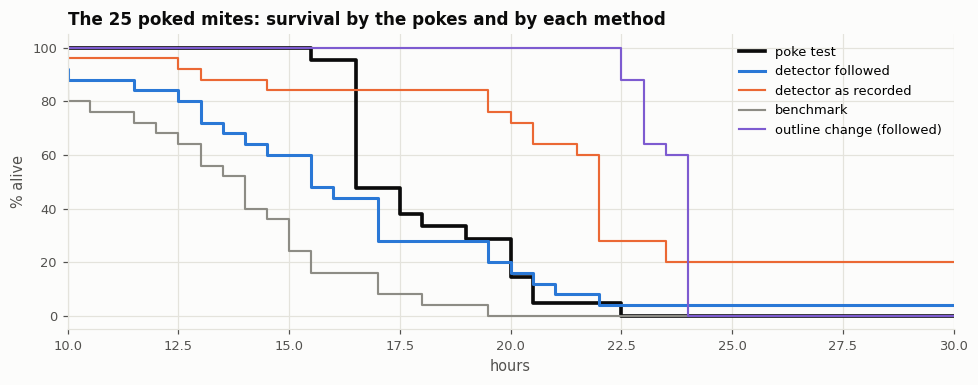

In [14]:
poke_rows = [{"n_recordings": len(te["times"]), "death": int(died["detector followed"][m]),
              "alive_until": bounds[te["ids"][m]][0], "dead_from": bounds[te["ids"][m]][1],
              "others": {name: int(died[name][m]) for name in
                         ("detector as recorded", "benchmark", "outline change (followed)")}} for m in poked]
curves = PokeSurvival.curves(poke_rows, te["times"])
hours = np.array(curves["times"]) / 60
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(hours, curves["poke"]["alive"], where="post", color=INK, lw=2.4, label="poke test")
ax.step(hours[:len(curves["detector"]["alive"])], curves["detector"]["alive"], where="post", color=BLUE, label="detector followed")
for (name, curve), color in zip(curves["others"].items(), (ORANGE, GREY, VIOLET)):
    ax.step(hours[:len(curve["alive"])], curve["alive"], where="post", color=color, lw=1.4, label=name)
ax.set_xlim(10, 30)
ax.set_xlabel("hours")
ax.set_ylabel("% alive")
ax.set_title(f"The {curves['poke']['n_mites']} poked mites: survival by the pokes and by each method", loc="left")
ax.legend(loc="upper right")
plt.tight_layout()

Why the outline change is late: its median over all 70 mites per pair of recordings, against the number of mites pushed in that pair. It stays high while the plates are handled and falls to the dead floor the moment the handling stops (recording 48). `GT_oct_2`, poked only before its second recording, falls to the same floor (about 0.03) as its mites die.

AUC     F1  balanced acc.  \
outline change, boxes run                                      
fixed                 calibrate  0.827  0.591          0.737   
                      test       0.759  0.347          0.696   
followed              calibrate  0.827  0.591          0.737   
                      test       0.802  0.359          0.707   

                                 still called moving  moving called still  \
outline change, boxes run                                                   
fixed                 calibrate                  163                   32   
                      test                       693                   57   
followed              calibrate                  163                   32   
                      test                       655                   57   

                                 death error (rec.)  deaths late  deaths early  
outline change, boxes run                                                       
fixed                 calibrate               1.857           20             0  
                      test                   21.615           26             0  
followed              calibrate               1.857           20             0  
                      test                   21.385           26             0

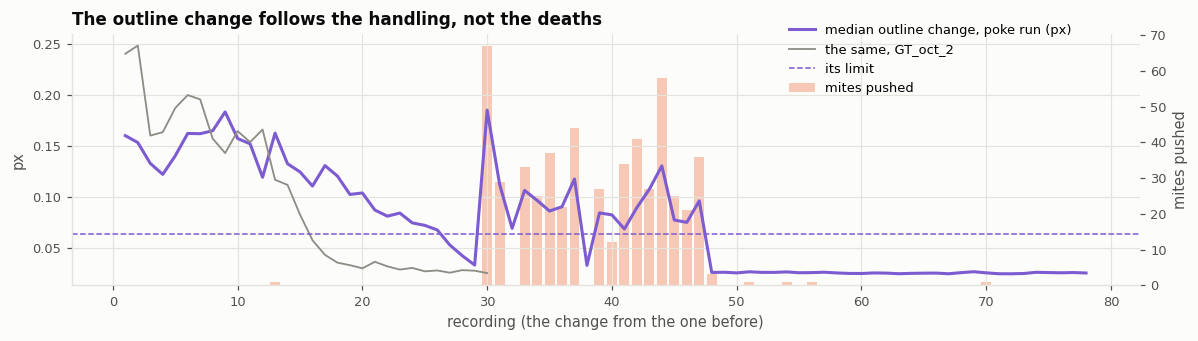

In [15]:
changes = np.array([[np.nan if value is None else value for value in row] for row in te["outline"]["follow"]])
pushed = (np.abs(np.diff(te["offset"], axis=1)) > 1).sum(axis=0)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(range(1, changes.shape[1]), np.nanmedian(changes[:, 1:], axis=0), color=VIOLET, label="median outline change, poke run (px)")
calibrate = np.array([[np.nan if value is None else value for value in row] for row in tr["outline"]["follow"]])
ax.plot(range(1, calibrate.shape[1]), np.nanmedian(calibrate[:, 1:], axis=0), color=GREY, lw=1.2, label="the same, GT_oct_2")
ax.axhline(te["outline_limit"], color=VIOLET, lw=1, ls="--", label="its limit")
ax2 = ax.twinx()
ax2.bar(range(1, changes.shape[1]), pushed, color=ORANGE, alpha=0.35, label="mites pushed")
ax2.grid(False)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_xlabel("recording (the change from the one before)")
ax.set_ylabel("px")
ax2.set_ylabel("mites pushed", color=MUTED)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.95))
ax.set_title("The outline change follows the handling, not the deaths", loc="left")
plt.tight_layout()

rows = []
for kind, label in (("fixed", "fixed"), ("follow", "followed")):
    for name, run in runs.items():
        values = np.array([[np.nan if v is None else v for v in row] for row in run["outline"][kind]])
        ok = run["labelled"] & ~np.isnan(values)
        rows.append({"outline change, boxes": label, "run": "calibrate" if name == TRAIN else "test",
                     "AUC": roc_auc_score(run["moving"][ok], values[ok]), **outcome(outline_calls(run, kind), run)})
display(pd.DataFrame(rows).set_index(["outline change, boxes", "run"]))

## 8. The death error: the detector against the benchmark

Followed, the detector still has a larger mean death error than the benchmark against the labels (2.96 recordings against 2.35). Mite by mite the two fail the opposite way: the benchmark misses real movements (4.8, 5.5 and 4.3 die 10 to 21 recordings early), and the detector makes a few lone weak calls long after the labelled death (0.17 to 0.48), each of which moves a death by up to 24 recordings.

In [16]:
def death_table(run, calls_by_name):
    labelled = run["labelled"].any(axis=1)
    lr = dc.LabelledRun(np.zeros(run["moving"].shape), run["moving"], run["labelled"])
    table = pd.DataFrame({"labels": lr.deaths(run["moving"]),
                          **{name: lr.deaths(calls) for name, calls in calls_by_name.items()}},
                         index=pd.Index(run["ids"], name="mite"))[labelled]
    return table

followed_calls = te["score"]["follow_stab"] >= t_follow
table = death_table(te, {"detector followed": followed_calls, "benchmark": np.array(te["benchmark"])})
table["late calls (rec.: score)"] = [", ".join(f"{at}: {te['score']['follow_stab'][m, at]:.2f}"
                                               for at in np.flatnonzero(followed_calls[m]) if at >= table.loc[mite_id, "labels"])
                                     for m, mite_id in enumerate(te["ids"]) if mite_id in table.index]
display(table[(table["detector followed"] != table["labels"]) | (table["benchmark"] != table["labels"])])

,labels,detector followed,benchmark,late calls (rec.: score)
mite,,,,
3.1,23,24,23,23: 0.21
3.2,23,24,24,23: 0.27
3.5,13,34,13,"22: 0.28, 33: 0.21"
4.1,34,41,34,40: 0.19
4.2,34,34,28,
4.3,34,34,24,
4.4,32,44,30,"35: 0.17, 42: 0.48, 43: 0.30"
4.5,21,32,21,31: 0.22
4.6,15,39,9,38: 0.20


**Are the detector's late calls noise?** In each, the pixel that changes most (round the followed box) is traced over the recording's ten frames. Noise or a glint would be one frame out of line. Instead a pixel on the mite's rim steps by 10 to 15 grey levels part way through and stays: a leg tip moving by about a pixel. The bottom rows are recordings labelled *moving* that score as low, for comparison: the same signature.

In [17]:
def peak_trace(mite_id, at):
    m = te["ids"].index(mite_id)
    number = te["roi_numbers"][m]
    x0, y0 = roi_of[number][:2]
    frames = loader.read_mite(te["recordings"][at], number).astype(np.float32)
    frames = frames.reshape(frames.shape[:3])
    x1, y1, x2, y2 = te["followed_boxes"][m][at]
    patch = frames[:, max(0, y1 - y0 - 4):max(0, y2 - y0 + 4), max(0, x1 - x0 - 4):max(0, x2 - x0 + 4)]
    change = np.abs(patch - np.median(patch, axis=0)).max(axis=0)
    y, x = np.unravel_index(change.argmax(), change.shape)
    return patch[:, y, x]

states = np.array(te["states"])
late = [(te["ids"][m], at) for m, at in np.argwhere(followed_calls & te["labelled"] & ~te["moving"])]
weak_moving = [(te["ids"][m], at) for m, at in np.argwhere((states == "moving") & followed_calls
                                                             & (te["score"]["follow_stab"] < 0.6))[:6]]
display(pd.DataFrame([{"mite": mite_id, "recording": at, "label": states[te["ids"].index(mite_id), at],
                       "score": te["score"]["follow_stab"][te["ids"].index(mite_id), at],
                       **{f"frame {k}": value for k, value in enumerate(peak_trace(mite_id, at))}}
                      for mite_id, at in late + weak_moving]).set_index(["mite", "recording"]).round({"score": 2, **{f"frame {k}": 0 for k in range(10)}}))

label  score  frame 0  frame 1  frame 2  frame 3  frame 4  \
mite recording                                                               
3.1  13          still   0.31    114.0    117.0    116.0    112.0    116.0   
     23          still   0.21    101.0    102.0    105.0    108.0    114.0   
3.2  23          still   0.27     94.0     92.0     93.0     92.0     93.0   
3.4  3           still   0.20    108.0    106.0    111.0    107.0    106.0   
3.5  22          still   0.28     63.0     65.0     63.0     62.0     52.0   
     33          still   0.21    165.0    161.0    169.0    167.0    164.0   
3.7  2           still   0.21    101.0     99.0     91.0     88.0     91.0   
3.8  5           still   0.19     69.0     64.0     71.0     69.0     74.0   
4.1  17          still   0.35    105.0    109.0    109.0    113.0    113.0   
     31          still   1.46    123.0    129.0    127.0    127.0    127.0   
     40          still   0.19    112.0    115.0    122.0    127.0    126.0   
4.4  19          still   0.21     96.0    107.0    111.0    107.0    106.0   
     35          still   0.17     81.0     87.0     81.0     77.0     77.0   
     42          still   0.48     93.0     89.0     74.0     76.0     81.0   
     43          still   0.30     96.0     92.0     94.0     95.0     95.0   
4.5  31          still   0.22     98.0     97.0    100.0     92.0     99.0   
4.6  38          still   0.20     99.0     98.0     98.0    100.0     97.0   
4.8  30          still   0.23     56.0     53.0     54.0     56.0     54.0   
5.5  29          still   0.20     99.0    102.0    103.0    112.0    113.0   
3.1  1          moving   0.53    128.0    131.0    131.0    147.0    137.0   
     14         moving   0.38     83.0     95.0     99.0     98.0    100.0   
3.2  11         moving   0.23     86.0     89.0     92.0     92.0     98.0   
     20         moving   0.51     76.0     91.0     83.0     74.0     76.0   
3.3  6          moving   0.19     95.0     91.0     93.0     97.0     98.0   
     18         moving   0.18    126.0    126.0    123.0    124.0    124.0   

                frame 5  frame 6  frame 7  frame 8  frame 9  
mite recording                                               
3.1  13           103.0    104.0    110.0    110.0    112.0  
     23           115.0    114.0    116.0    114.0    109.0  
3.2  23            91.0     89.0     79.0     76.0     78.0  
3.4  3            103.0    102.0    101.0     98.0     96.0  
3.5  22            54.0     49.0     52.0     51.0     53.0  
     33           167.0    168.0    166.0    158.0    162.0  
3.7  2             89.0     92.0     91.0     88.0     93.0  
3.8  5             75.0     77.0     74.0     77.0     77.0  
4.1  17           115.0    118.0    117.0    116.0    122.0  
     31           126.0    126.0    127.0    127.0     84.0  
     40           123.0    123.0    125.0    120.0    124.0  
4.4  19           108.0    109.0    106.0    111.0    108.0  
     35            79.0     78.0     79.0     80.0     84.0  
     42            81.0     84.0     84.0     87.0     91.0  
     43            97.0     85.0     83.0     82.0     86.0  
4.5  31            99.0    102.0    102.0    103.0    101.0  
4.6  38            97.0    101.0    107.0    111.0    111.0  
4.8  30            56.0     55.0     54.0     42.0     54.0  
5.5  29           117.0    117.0    120.0    114.0    118.0  
3.1  1            132.0    134.0    131.0    129.0    129.0  
     14           102.0    100.0     98.0     99.0     95.0  
3.2  11            97.0     96.0     98.0    102.0    101.0  
     20            78.0     74.0     73.0     77.0     76.0  
3.3  6            100.0    106.0    105.0    104.0    113.0  
     18           125.0    124.0    116.0    124.0    121.0

**The pokes side with the detector.** Six labelled deaths contradict the poke test: five mites labelled dead before recording 30 answered the poke after recording 29 (3.8, 4.5, 4.6, 4.7 and 5.3), and 4.3 is labelled moving one recording after the poke it did not answer. For those, the true death lies between the last poke answered and the first one not: each method's error is its distance from that interval. The other mites keep their labelled death.

In [18]:
def death_errors(moving, show_contradicted=True):
    # each method's mean death error against labels `moving`, as they are and corrected by the pokes
    lr = dc.LabelledRun(np.zeros(moving.shape), moving, te["labelled"])
    label_death = lr.deaths(moving).astype(float)
    low, high = label_death.copy(), label_death.copy()
    contradicted = []
    for m, mite_id in enumerate(te["ids"]):
        if not te["labelled"][m].any() or mite_id not in bounds:
            continue
        alive_until, dead_from = bounds[mite_id]
        if alive_until is not None and label_death[m] < alive_until:
            low[m], high[m] = alive_until, np.inf if dead_from is None else dead_from
            contradicted.append(mite_id)
        elif dead_from is not None and label_death[m] > dead_from:
            low[m], high[m] = min(low[m], dead_from), dead_from
            contradicted.append(mite_id)
    if show_contradicted:
        print("labelled deaths the pokes contradict:", ", ".join(contradicted))
    with_moving = moving.any(axis=1)
    rows = []
    for name, calls in (("detector as recorded", te["score"]["as recorded"] >= t_recorded),
                        ("detector followed", followed_calls),
                        ("detector followed, lone weak calls dropped", without_lone_weak(te["score"]["follow_stab"], t_follow)),
                        ("benchmark", np.array(te["benchmark"]))):
        death = lr.deaths(calls).astype(float)
        to_poke = np.where(death < low, low - death, np.where(death > high, death - high, 0))
        rows.append({"method": name, "F1": outcome(calls, {**te, "moving": moving})["F1"],
                     "vs labels": np.abs(death - label_death)[with_moving].mean(),
                     "vs labels corrected by the pokes": to_poke[with_moving].mean()})
    return pd.DataFrame(rows).set_index("method").rename_axis(columns="mean death error (recordings)")

display(death_errors(te["moving"]))

labelled deaths the pokes contradict: 3.8, 4.3, 4.5, 4.6, 4.7, 5.3


mean death error (recordings),F1,vs labels,vs labels corrected by the pokes
method,,,
detector as recorded,0.719,11.538,9.115
detector followed,0.948,2.962,2.231
"detector followed, lone weak calls dropped",0.953,1.154,2.692
benchmark,0.928,2.346,3.808


Against the labels as they are, the benchmark wins (2.35 against 2.96). Against the labels corrected by the pokes, the detector wins (2.23 against 3.81): the benchmark's early deaths are what the pokes contradict. Dropping lone weak calls looked good against the labels (1.15) only because it agrees with their mistakes; against the corrected labels it is worse (2.69), so it is not worth having.

What remains of the detector's error is three mites the pokes say nothing against: 3.5 (+21), 4.4 (+12) and 4.1 (+7), all from lone calls of 0.17 to 0.28 with a real-looking leg-tip step. Either the labels missed a twitch, or a dead mite's leg still moves (a drying leg curling). Only the clips can tell: 3.5 r22 and r33, 4.4 r35, r42 and r43, 4.1 r40. They all fall inside the review band of section 6, which is what the band is for.

### Checked by eye (20 October 2026)

The user checked the recordings the death comparison turns on, on the Discobox (recording numbers here count from 0; the app's are one more). Four lone calls were real movements the labels had missed (3.5 r22, 4.4 r42 and r43, 4.1 r40, 4.6 r38); three were still (3.5 r33, 4.4 r35, 4.5 r31). 4.3 r33 (labelled moving after a poke it did not answer) is not checked yet. With these as labels:

In [19]:
EYE = {("3.5", 22): True, ("3.5", 33): False, ("4.4", 35): False, ("4.4", 42): True, ("4.4", 43): True,
       ("4.1", 40): True, ("4.6", 38): True, ("4.5", 31): False}
checked = te["moving"].copy()
for (mite_id, at), moved in EYE.items():
    checked[te["ids"].index(mite_id), at] = moved
display(death_errors(checked))
table = death_table({**te, "moving": checked}, {"detector followed": followed_calls, "benchmark": np.array(te["benchmark"])})
display(table[(table["detector followed"] != table["labels"]) | (table["benchmark"] != table["labels"])].drop(columns=[], errors="ignore"))

labelled deaths the pokes contradict: 3.8, 4.3, 4.5, 4.7, 5.3


mean death error (recordings),F1,vs labels,vs labels corrected by the pokes
method,,,
detector as recorded,0.729,9.500,8.000
detector followed,0.958,0.923,1.115
"detector followed, lone weak calls dropped",0.956,1.500,2.462
benchmark,0.918,4.385,5.269


,labels,detector followed,benchmark
mite,,,
3.1,23,24,23
3.2,23,24,24
3.5,23,34,13
4.1,41,41,34
4.2,34,34,28
4.3,34,34,24
4.4,44,44,30
4.5,21,32,21
4.6,39,39,9


With the checked labels the followed detector's death error is **0.92** recordings, the benchmark's 4.38 (1.12 against 5.27 with the pokes too), and its F1 0.958 against 0.918. Half of the moved lone calls were real: the labels had missed a leg moving, and the benchmark misses them too, so its deaths come early. What is left of the detector's error is two calls the eye saw still (3.5 r33, 4.5 r31: 0.21 and 0.22, inside the review band) and two deaths one recording late. For 4.5 even that call fits the poke test (alive at 30, dead from 33), while its labelled death (21) does not.

## 9. How long and how fast a recording must be

The three labelled sessions of 2025 were recorded at 30 fps for 1 s. `scripts/recording_length.py` scores every recording again (the score in use, mites followed), cut down to shorter and slower recordings of itself, so that only the recording changes: the same mites, the same labels. Below, the recordings each way calls wrong at its best threshold, of 515 labelled.

In [20]:
lengths = json.loads((ROOT / "results" / "scripts" / "recording_length.json").read_text(encoding="utf-8"))
rows = []
for way, setting in lengths["ways"].items():
    scores, moving = [], []
    for session in lengths["sessions"].values():
        for m, states in enumerate(session["states"]):
            for at, state in enumerate(states):
                if state in ("moving", "still"):
                    scores.append(session["scores"][way][m][at]); moving.append(state == "moving")
    scores, moving = np.log(np.array(scores) + 1e-3), np.array(moving)
    rows.append({"fps": setting["fps"], "seconds": round(setting["seconds"], 2),
                 "frames": int(round(setting["seconds"] * setting["fps"])),
                 "AUC": roc_auc_score(moving, scores),
                 "wrong at the best threshold": min(int(((scores >= t) != moving).sum()) for t in np.unique(scores)),
                 "still mites' median score": float(np.exp(np.median(scores[~moving])))})
lengths_table = pd.DataFrame(rows)
display(lengths_table.pivot(index="seconds", columns="fps", values="wrong at the best threshold"))
display(lengths_table.set_index(["fps", "seconds"]))

fps,10,15,30
seconds,,,
0.33,50,54,50
0.50,39,32,33
0.67,21,23,18
1.00,4,2,1


frames    AUC  wrong at the best threshold  \
fps seconds                                               
10  0.33          3  0.925                           50   
    0.50          5  0.941                           39   
    0.67          7  0.979                           21   
    1.00         10  0.998                            4   
15  0.33          5  0.909                           54   
    0.50          8  0.943                           32   
    0.67         10  0.967                           23   
    1.00         15  1.000                            2   
30  0.33         10  0.905                           50   
    0.50         15  0.940                           33   
    0.67         20  0.974                           18   
    1.00         30  1.000                            1   

             still mites' median score  
fps seconds                             
10  0.33                         0.061  
    0.50                         0.058  
    0.67                         0.053  
    1.00                         0.047  
15  0.33                         0.053  
    0.50                         0.050  
    0.67                         0.047  
    1.00                         0.041  
30  0.33                         0.045  
    0.50                         0.038  
    0.67                         0.035  
    1.00                         0.031

The length of a recording matters far more than its frame rate. Over 1 s, 10, 15 or 30 fps call 4, 2 and 1 of 515 wrong: more frames lower the noise a little (still mites score 0.047, 0.041, 0.031). Shorter recordings miss the movement: over a third of a second about 50 are wrong at any frame rate, and 30 frames over 0.33 s do far worse than 10 over 1 s. A mite often moves a leg once or twice a second. Part of that is how this is tested (the labels were made watching 1 s), but the curve still falls steeply at 1 s, so longer recordings very likely help further.

Since 20 October 2026 every live recording is 3 s at 30 fps (90 frames), fixed (`classes/live/settings.py`): a threshold only fits recordings as long and as fast as those it was calibrated on. The thresholds above (0.165 for 10 frames at 10 fps) do not fit those; a ground-truth run at 3 s and 30 fps sets the next one.

## What to do

1. **Record with following on.** These runs were made before 28afd12; with it, the replay says the detector beats the benchmark on this run, at the threshold of `GT_oct_2`. Nothing in the scoring needs to change for that.
2. **Re-analyse the old runs with following.** A saved run without boxes per recording is analysed with its boxes as found (`RoiRecordings.placements()` gives None). Its blobs are saved, so `MotionAnalysis` could follow them as this notebook replays: worth adding if these runs are to be reported.
3. **Keep checking close calls by eye.** With following, a band of about 0.12 to 0.5 costs about one check per mite and fixed every remaining death here.
4. **Save the checks of section 8 into the ground truth**, and look again at the mites the pokes contradict (3.8, 4.3, 4.5, 4.7 and 5.3; 4.3 r33 is not checked yet).
5. **Calibrate again on a ground-truth run at 3 s and 30 fps**, the recording every live run makes since 20 October 2026 (section 9). 0.165, calibrated here on 10 frames at 10 fps, and 0.31 in `config.yaml` both fit the old recordings only.
6. **Don't use the outline change between recordings across pokes.** It measures *alive* and is fooled by handling. If it is kept, it should skip the recordings next to a poke round, not only the pairs with a pushed mite.
7. **Light:** nothing to do on this evidence. The light within a recording is steady and the score already takes out the plate's light frame by frame.